<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How far did measured water level sit from the tide prediction?

Compare six-minute observations with astronomical tide predictions at **The Battery, NOAA station 8518750**, on **1 October 2026 UTC**. Align station, timestamp and vertical datum exactly, inspect coverage and quality fields, and compute observed minus predicted height. Then vary a descriptive residual threshold while holding the responses fixed.

The default replays **two unchanged actual NOAA responses captured on 14 November 2026** through the real Tides worker. Heights are metres relative to **MLLW**, not absolute elevation. The residual is not a pure weather or storm-surge measurement; it can reflect several physical and measurement differences. This historical comparison is not a navigation or flood-warning product. [Setup and provenance](README.md).

## Choose a descriptive threshold

`RESIDUAL_THRESHOLD_M` is a finite number **0–1 metre**, default **0.15**, experiment **0.20**. Count paired observations with **absolute residual strictly greater** than the threshold. Equality belongs below/at the threshold. This is an analytical cutoff, not an official warning level.

`DATA_MODE` is **replay** or **live**. Both modes use the same station, UTC day, MLLW datum, metric units and six-minute prediction interval. Dates in the worker API are inclusive days; SQL uses the equivalent interval **[2026-10-01 00:00, 2026-10-02 00:00) UTC**. Restart and run all after changing parameters.

In [1]:
DATA_MODE = "replay"  # "live" directly requests the same historical day.
RESIDUAL_THRESHOLD_M = 0.15  # Absolute residual cutoff in metres; experiment: 0.20.

In [2]:
import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import audit, chart, cleanup, configure, prose, theme

server, thread, previous, run_utc, provenance = configure(DATA_MODE, RESIDUAL_THRESHOLD_M)
source_label = (
    "NOAA recorded responses • 2026-11-14 capture"
    if DATA_MODE == "replay"
    else f"NOAA live retrieval • {run_utc[:19]} UTC"
)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tides/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tides/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tides/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tides/notebooks/pyproject.toml.

## Attach the published native release

The literal GitHub transport loads the platform asset for **v0.1.0**. No Bun installation, worker source tree or local binary is required. First launch needs network for the native asset and signed VGI extension. The separately locked Python environment uses published Haybarn 2.0.0rc11.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tides' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-tides@v0.1.0');
CREATE TABLE settings AS SELECT {{ RESIDUAL_THRESHOLD_M }}::DOUBLE AS threshold_m;
SELECT * FROM tides.main.products WHERE sql_function IN ('tide_predictions','water_levels');

Running query in 'DuckDBPyConnection'

1 rows affected.

,sql_function,noaa_product,output_units
0,tide_predictions,predictions,m
1,water_levels,water_level,m


In [4]:
prose(
    f"**{source_label}.** Measurement day: **2026-10-01 UTC**; station **8518750**; datum **MLLW**. "
    f"Archived capture times: predictions **{provenance['predictions']['captured_utc']}**, "
    f"observations **{provenance['water_level']['captured_utc']}**. "
    "They are independent reads. Worker `fetched_at` records this run's read time; "
    "in replay it is the local replay read, not the upstream capture time."
)

**NOAA recorded responses • 2026-11-14 capture.** Measurement day: **2026-10-01 UTC**; station **8518750**; datum **MLLW**. Archived capture times: predictions **2026-11-14T10:30:52.308437+00:00**, observations **2026-11-14T10:30:52.437873+00:00**. They are independent reads. Worker `fetched_at` records this run's read time; in replay it is the local replay read, not the upstream capture time.

## Materialize both products and inspect availability

Observations and predictions share a height column but represent different products. Fetch each once with explicit datum and interval. Preserve quality, flags and missing heights. The diagnostic table reports each source’s available rows and UTC extent; it does not turn missing observations into zero. Worker source URLs in replay refer to loopback; the exact original NOAA URLs are in the provenance file.

In [5]:
%%sql
CREATE TABLE predictions AS SELECT * FROM tides.main.tide_predictions(
    '8518750','2026-10-01','2026-10-01',datum:='MLLW',step:='6');
CREATE TABLE observations AS SELECT * FROM tides.main.water_levels(
    '8518750','2026-10-01','2026-10-01',datum:='MLLW');
SELECT 'predictions' AS product,count(*) AS rows,count(height_m) AS available_heights,
    min(time) AT TIME ZONE 'UTC' AS first_utc,max(time) AT TIME ZONE 'UTC' AS last_utc,
    min(datum) AS datum,min(fetched_at) AT TIME ZONE 'UTC' AS worker_read_utc FROM predictions
UNION ALL
SELECT 'observations',count(*),count(height_m),min(time) AT TIME ZONE 'UTC',
    max(time) AT TIME ZONE 'UTC',min(datum),min(fetched_at) AT TIME ZONE 'UTC' FROM observations;

Running query in 'DuckDBPyConnection'

240 rows affected.

240 rows affected.

,product,rows,available_heights,first_utc,last_utc,datum,worker_read_utc
0,predictions,240,240,2026-10-01,2026-10-01 23:54:00,MLLW,2026-11-14 10:36:54.630
1,observations,240,240,2026-10-01,2026-10-01 23:54:00,MLLW,2026-11-14 10:36:54.635


## Join exact keys and apply an explicit quality rule

Generate the expected 240 six-minute timestamps, then left join both products on **station ID, time and datum**. Keep a row for every expected timestamp, including gaps. No nearest-time matching or interpolation occurs.

For this analysis, accept observations only when NOAA quality is **v (verified)** and the returned flag string is exactly **0,0,0,0**. Preliminary, unknown or other flagged rows remain in the diagnostic counts and are excluded. This conservative rule is explicit; the notebook does not assign meanings to every possible flag or certify operational suitability. Required missing/empty usable data fails clearly before plotting.

In [6]:
%%sql
CREATE TABLE grid AS SELECT '8518750' AS station_id,'MLLW' AS datum,t AS time
FROM generate_series(TIMESTAMPTZ '2026-10-01 00:00:00+00',
    TIMESTAMPTZ '2026-10-01 23:54:00+00',INTERVAL '6 minutes') AS times(t);
CREATE TABLE aligned AS
SELECT g.*,p.height_m AS predicted_m,o.height_m AS observed_m,o.quality,o.flags,
    CASE WHEN p.time IS NULL THEN 'missing prediction row'
         WHEN o.time IS NULL THEN 'missing observation row'
         WHEN p.height_m IS NULL OR o.height_m IS NULL THEN 'missing height'
         WHEN o.quality IS DISTINCT FROM 'v' OR o.flags IS DISTINCT FROM '0,0,0,0' THEN 'excluded quality/flags'
         ELSE 'usable pair' END AS assessment
FROM grid g LEFT JOIN predictions p USING(station_id,time,datum)
LEFT JOIN observations o USING(station_id,time,datum);
CREATE TABLE paired AS SELECT *,observed_m-predicted_m AS residual_m,
    abs(observed_m-predicted_m) AS absolute_residual_m
FROM aligned WHERE assessment='usable pair';
SELECT assessment,count(*) AS expected_timestamps FROM aligned GROUP BY assessment ORDER BY assessment;

Running query in 'DuckDBPyConnection'

240 rows affected.

240 rows affected.

240 rows affected.

,assessment,expected_timestamps
0,usable pair,240


In [7]:
%%sql summary <<
SELECT count(*) AS paired_samples,min(residual_m) AS minimum_residual_m,
    max(residual_m) AS maximum_residual_m,avg(residual_m) AS mean_residual_m,
    sqrt(avg(residual_m*residual_m)) AS rms_difference_m,
    count(*) FILTER(WHERE absolute_residual_m>(SELECT threshold_m FROM settings)) AS above_threshold,
    100.0*count(*) FILTER(WHERE absolute_residual_m>(SELECT threshold_m FROM settings))/nullif(count(*),0) AS above_percent
FROM paired;

Running query in 'DuckDBPyConnection'

In [8]:
display(summary)
if int(summary.iloc[0].paired_samples) == 0:
    raise ValueError("No usable paired water-level observations after coverage and quality checks")
r = summary.iloc[0]
prose(
    f"**{int(r.paired_samples)} paired samples** remain. Observed minus predicted height ranges from "
    f"**{r.minimum_residual_m:.3f} to {r.maximum_residual_m:.3f} m**, "
    f"with mean **{r.mean_residual_m:.3f} m** "
    f"and RMS difference **{r.rms_difference_m:.3f} m**. "
    "RMS is a difference summary, not a calibrated prediction uncertainty interval. "
    "Sample percentages below describe available pairs, not continuous time above a level."
)

,paired_samples,minimum_residual_m,maximum_residual_m,mean_residual_m,rms_difference_m,above_threshold,above_percent
0,240,0.032,0.243,0.131975,0.141591,82,34.166667


**240 paired samples** remain. Observed minus predicted height ranges from **0.032 to 0.243 m**, with mean **0.132 m** and RMS difference **0.142 m**. RMS is a difference summary, not a calibrated prediction uncertainty interval. Sample percentages below describe available pairs, not continuous time above a level.

In [9]:
%%sql series <<
SELECT time AT TIME ZONE 'UTC' AS time_utc,predicted_m,observed_m,residual_m,absolute_residual_m
FROM paired ORDER BY time;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


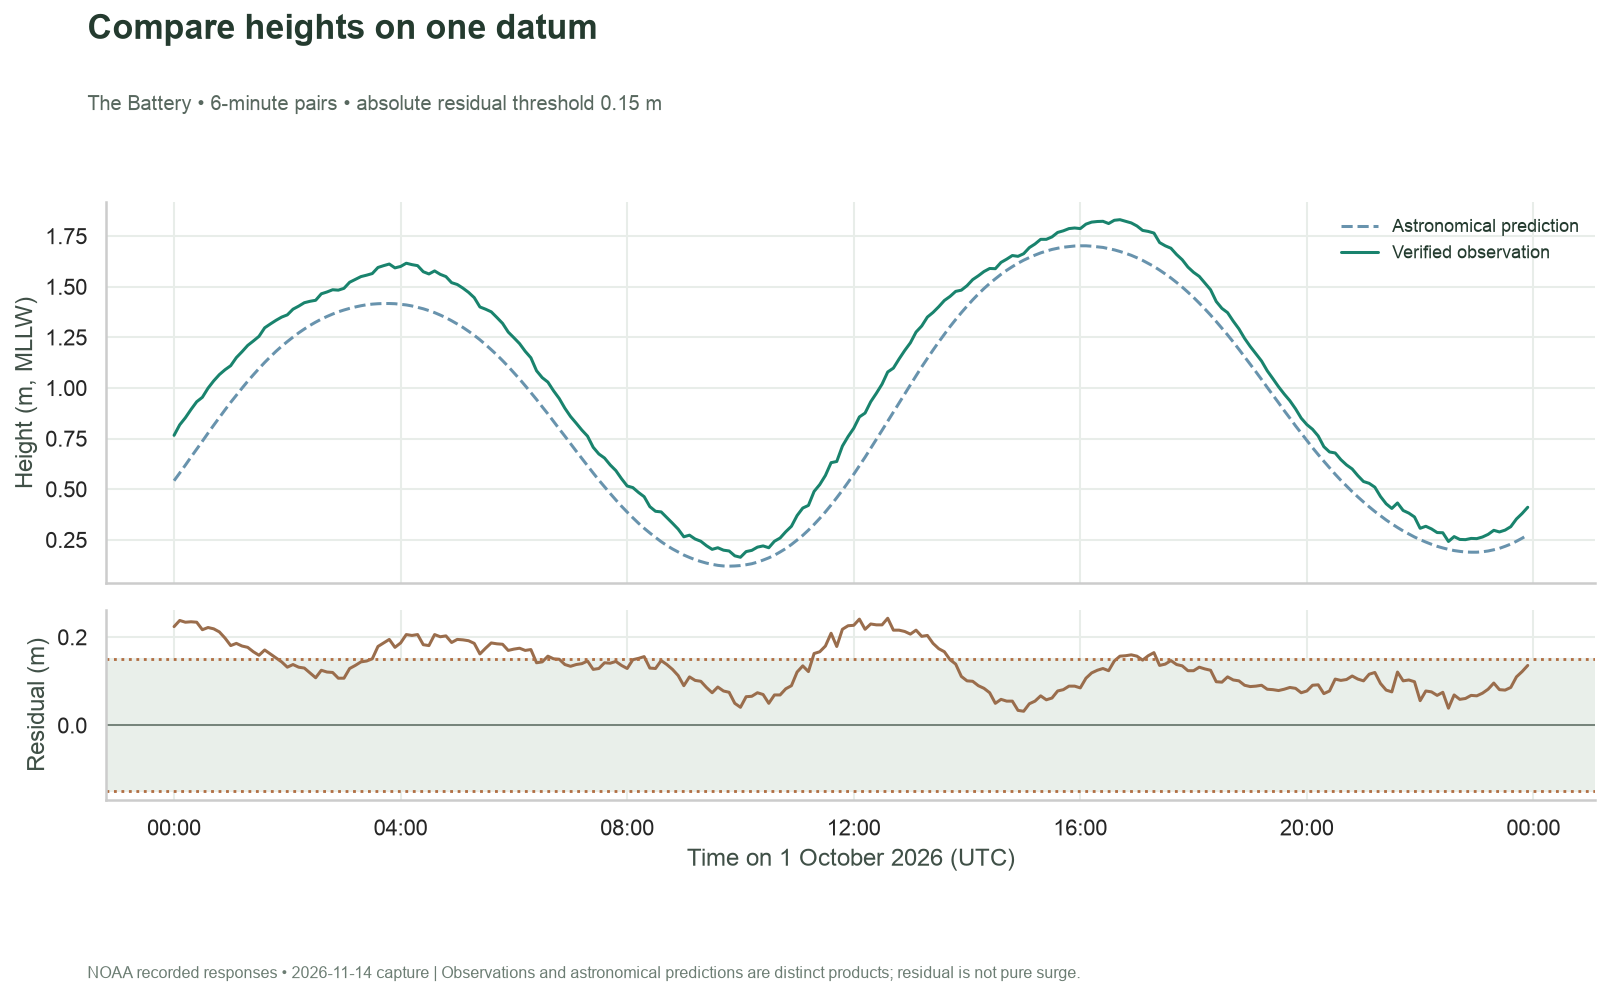

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(
    series.time_utc, series.predicted_m, color="#6893AD", linestyle="--", label="Astronomical prediction"
)
axes[0].plot(series.time_utc, series.observed_m, color="#19836D", label="Verified observation")
axes[0].set_ylabel("Height (m, MLLW)")
axes[0].legend(loc="upper right", fontsize=9)
axes[1].axhspan(-RESIDUAL_THRESHOLD_M, RESIDUAL_THRESHOLD_M, color="#E9EFEA", label="Within threshold")
axes[1].axhline(0, color="#77857C", linewidth=1)
axes[1].plot(series.time_utc, series.residual_m, color="#9A6D4C", label="Observed − predicted")
axes[1].axhline(RESIDUAL_THRESHOLD_M, color="#B16E43", linestyle=":", linewidth=1.4)
axes[1].axhline(-RESIDUAL_THRESHOLD_M, color="#B16E43", linestyle=":", linewidth=1.4)
axes[1].set_ylabel("Residual (m)")
axes[1].set_xlabel("Time on 1 October 2026 (UTC)")
axes[1].xaxis.set_major_locator(mdates.HourLocator(interval=4))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
chart(
    fig,
    "Compare heights on one datum",
    f"The Battery • 6-minute pairs • absolute residual threshold {RESIDUAL_THRESHOLD_M:.2f} m",
    source_label
    + " | Observations and astronomical predictions are distinct products; residual is not pure surge.",
)

## Count exceedances without turning a sample into a duration

The empirical cumulative distribution shows the fraction of paired samples at or below each absolute residual. At the selected threshold, its complement is the strictly-above fraction. Repeated values receive the same cumulative fraction. These 240 expected time positions are samples, not a continuous reconstruction between them; excluded data would also change the denominator.

In [11]:
%%sql distribution <<
SELECT absolute_residual_m,cume_dist() OVER(ORDER BY absolute_residual_m) AS fraction_at_or_below
FROM paired ORDER BY absolute_residual_m;

Running query in 'DuckDBPyConnection'

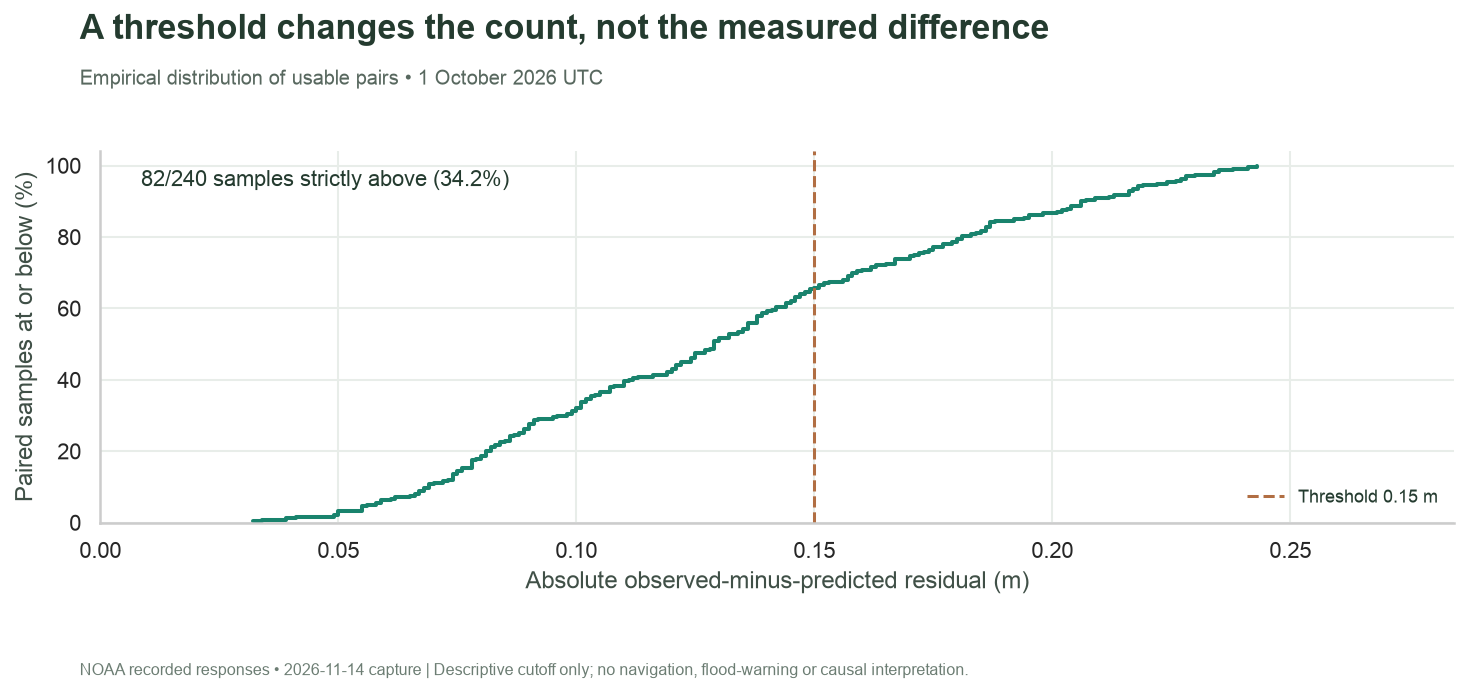

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.step(
    distribution.absolute_residual_m,
    100 * distribution.fraction_at_or_below,
    where="post",
    color="#19836D",
    linewidth=2,
)
ax.axvline(
    RESIDUAL_THRESHOLD_M, color="#B16E43", linestyle="--", label=f"Threshold {RESIDUAL_THRESHOLD_M:.2f} m"
)
ax.set_xlim(0, max(float(distribution.absolute_residual_m.max()), RESIDUAL_THRESHOLD_M) * 1.15 + 0.005)
ax.set_ylim(0, 104)
ax.set_xlabel("Absolute observed-minus-predicted residual (m)")
ax.set_ylabel("Paired samples at or below (%)")
ax.legend(loc="lower right", fontsize=9)
ax.text(
    0.03,
    0.95,
    f"{int(r.above_threshold)}/{int(r.paired_samples)} samples strictly above ({r.above_percent:.1f}%)",
    transform=ax.transAxes,
    va="top",
    fontsize=11,
)
chart(
    fig,
    "A threshold changes the count, not the measured difference",
    "Empirical distribution of usable pairs • 1 October 2026 UTC",
    source_label + " | Descriptive cutoff only; no navigation, flood-warning or causal interpretation.",
)

## Verify the alignment and units

The grid makes missing rows visible; these checks prevent duplicate source keys from multiplying pairs, verify that source timestamps stay inside the requested UTC day, and reconcile the signed difference. They allow missing or excluded timestamps without treating them as zero.

In [13]:
%%sql checks <<
SELECT 'unique prediction keys' AS check_name,NOT EXISTS(SELECT station_id,time,datum FROM predictions GROUP BY ALL HAVING count(*)<>1) AS passed
UNION ALL SELECT 'unique observation keys',NOT EXISTS(SELECT station_id,time,datum FROM observations GROUP BY ALL HAVING count(*)<>1)
UNION ALL SELECT 'expected six-minute grid',(SELECT count(*)=240 AND count(DISTINCT time)=240 FROM grid)
UNION ALL SELECT 'alignment preserves grid',(SELECT count(*) FROM aligned)=(SELECT count(*) FROM grid)
UNION ALL SELECT 'source dates inside UTC day',NOT EXISTS(SELECT 1 FROM (SELECT time FROM predictions UNION ALL SELECT time FROM observations) WHERE time<TIMESTAMPTZ '2026-10-01 00:00:00+00' OR time>=TIMESTAMPTZ '2026-10-02 00:00:00+00')
UNION ALL SELECT 'source station and datum agree',NOT EXISTS(SELECT 1 FROM (SELECT station_id,datum FROM predictions UNION ALL SELECT station_id,datum FROM observations) WHERE station_id<>'8518750' OR datum<>'MLLW')
UNION ALL SELECT 'every source timestamp lies on grid',NOT EXISTS((SELECT time FROM predictions EXCEPT SELECT time FROM grid) UNION ALL (SELECT time FROM observations EXCEPT SELECT time FROM grid))
UNION ALL SELECT 'paired observations pass quality rule',NOT EXISTS(SELECT 1 FROM paired WHERE quality IS DISTINCT FROM 'v' OR flags IS DISTINCT FROM '0,0,0,0')
UNION ALL SELECT 'usable values present and finite',NOT EXISTS(SELECT 1 FROM paired WHERE predicted_m IS NULL OR observed_m IS NULL OR NOT isfinite(predicted_m) OR NOT isfinite(observed_m))
UNION ALL SELECT 'residual reconstructs observation',NOT EXISTS(SELECT 1 FROM paired WHERE abs(predicted_m+residual_m-observed_m)>1e-12)
UNION ALL SELECT 'absolute residual preserves sign magnitude',NOT EXISTS(SELECT 1 FROM paired WHERE absolute_residual_m<>abs(residual_m))
UNION ALL SELECT 'threshold partitions usable pairs',(SELECT count(*) FROM paired)=(SELECT count(*) FILTER(WHERE absolute_residual_m>(SELECT threshold_m FROM settings))+count(*) FILTER(WHERE absolute_residual_m<=(SELECT threshold_m FROM settings)) FROM paired);

Running query in 'DuckDBPyConnection'

In [14]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + audit(server))

,check_name,passed
0,unique prediction keys,True
1,unique observation keys,True
2,expected six-minute grid,True
3,alignment preserves grid,True
4,source dates inside UTC day,True
5,source station and datum agree,True
6,every source timestamp lies on grid,True
7,paired observations pass quality rule,True
8,usable values present and finite,True
9,residual reconstructs observation,True


**All 12 SQL checks passed.** Replay audit: exactly one prediction and one observation request with recorded parameters.

## Experiment: raise the descriptive cutoff

Change only **RESIDUAL_THRESHOLD_M from 0.15 to 0.20 m** in replay mode and rerun in a separate output directory. Predict a count that cannot increase. Compare the threshold band and exceedance annotation; the height curves, residual values, empirical distribution and paired-sample denominator must remain fixed.

The result measures sensitivity to an analytical cutoff, not risk or an official alert threshold. The source response does not identify the causes of residual water level. Restore **0.15** to return to the saved example; [the README](README.md) gives experiment and live commands.

In [15]:
connection.close()
cleanup(server, thread, previous)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>